### 1.Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

### 2.Upload Dataset

In [15]:
df = pd.read_excel("sample_-_superstore.xls")

### 3.Sales Distribution Analysis

count    10194.000000
mean       228.225854
std        619.906839
min          0.444000
25%         17.220000
50%         53.910000
75%        209.500000
max      22638.480000
Name: Sales, dtype: float64


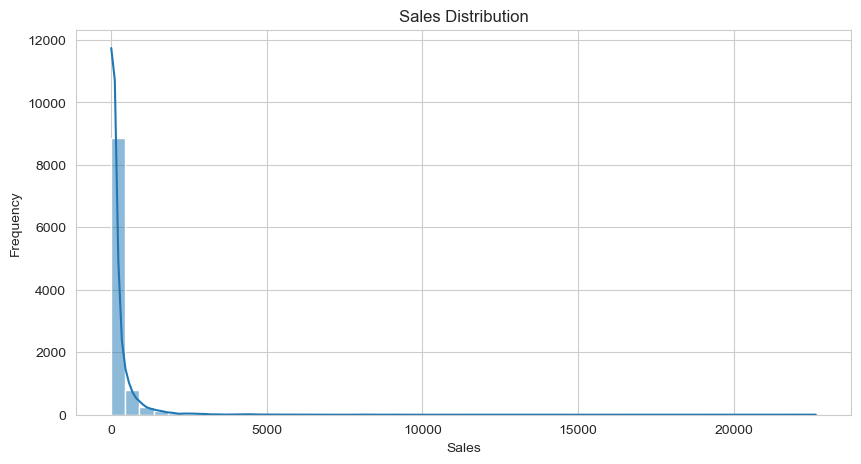

In [5]:
print(df['Sales'].describe())

plt.figure(figsize=(10,5))
sns.histplot(df['Sales'], bins=50, kde=True)

plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

### 4.Profit Distribution Analysis

count    10194.000000
mean        28.673417
std        232.465115
min      -6599.978000
25%          1.760800
50%          8.690000
75%         29.297925
max       8399.976000
Name: Profit, dtype: float64


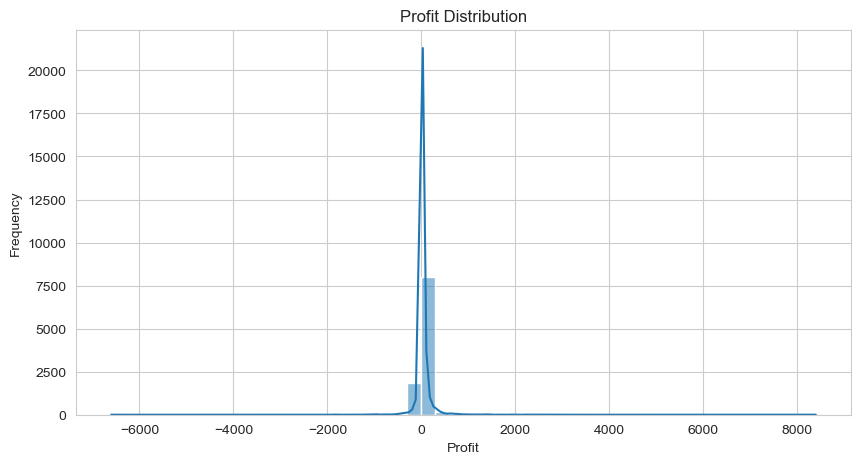

In [6]:
print(df['Profit'].describe())

plt.figure(figsize=(10,5))
sns.histplot(df['Profit'], bins=50, kde=True)

plt.title('Profit Distribution')
plt.xlabel('Profit')
plt.ylabel('Frequency')
plt.show()

### 5.Order Distribution Analysis

In [7]:
order_data = df.groupby('Order ID').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order Date': 'min'
}).reset_index()

print("Total Unique Orders:", order_data['Order ID'].nunique())

print(order_data[['Sales', 'Profit']].describe())

Total Unique Orders: 5111
              Sales       Profit
count   5111.000000  5111.000000
mean     455.201400    57.189750
std      949.794017   342.232557
min        0.556000 -6892.374800
25%       37.304000     2.047050
50%      149.200000    16.240800
75%      508.365000    68.668400
max    23661.228000  8762.389100


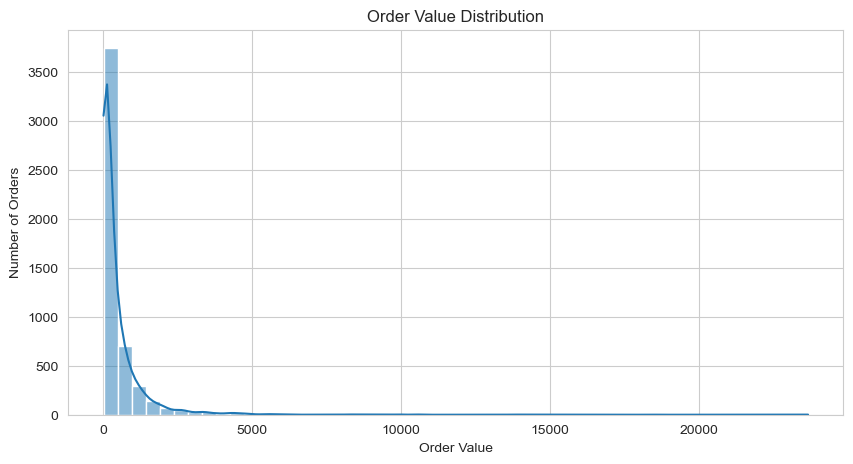

In [8]:
plt.figure(figsize=(10,5))
sns.histplot(order_data['Sales'], bins=50, kde=True)

plt.title('Order Value Distribution')
plt.xlabel('Order Value')
plt.ylabel('Number of Orders')
plt.show()

### 6.Category-wise Sales and Profit

In [12]:
category_analysis = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

category_analysis.rename(
    columns={'Order ID': 'Total Orders'},
    inplace=True
)

print(category_analysis)

          Category        Sales       Profit  Total Orders
0        Furniture  754747.7613   19729.9956          1819
1  Office Supplies  731893.3140  126023.4434          3812
2       Technology  839893.2790  146543.3756          1560


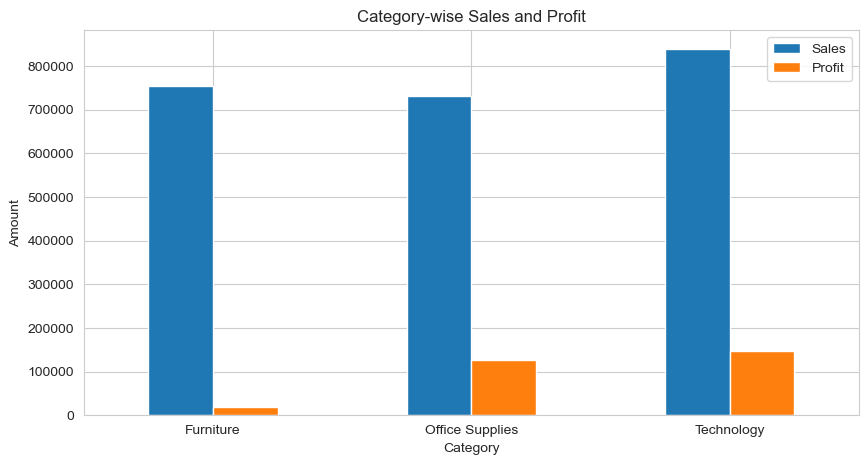

In [13]:
category_analysis.plot(
    x='Category',
    y=['Sales', 'Profit'],
    kind='bar',
    figsize=(10,5)
)

plt.title('Category-wise Sales and Profit')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.show()

### 7. Region-wise Sales and Profit

In [16]:
region_analysis = df.groupby('Region').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

region_analysis.rename(
    columns={'Order ID': 'Total Orders'},
    inplace=True
)

print(region_analysis)

    Region        Sales       Profit  Total Orders
0  Central  503170.6728   39865.3070          1179
1     East  691828.1680   94883.2603          1475
2    South  391721.9050   46749.4303           822
3     West  739813.6085  110798.8170          1635


### 8. Monthly Sales and Order Trends

In [10]:
monthly_analysis = order_data.copy()

monthly_analysis['Month'] = (
    monthly_analysis['Order Date'].dt.to_period('M')
)

monthly_trend = monthly_analysis.groupby('Month').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'count'
}).reset_index()

monthly_trend['Month'] = (
    monthly_trend['Month'].astype(str)
)

print(monthly_trend.head())

     Month      Sales     Profit  Order ID
0  2023-01  14518.055  2539.3907        33
1  2023-02   4519.892   862.3084        28
2  2023-03  56933.909   693.4499        72
3  2023-04  28295.345  3488.8352        66
4  2023-05  26319.767  3196.3918        72


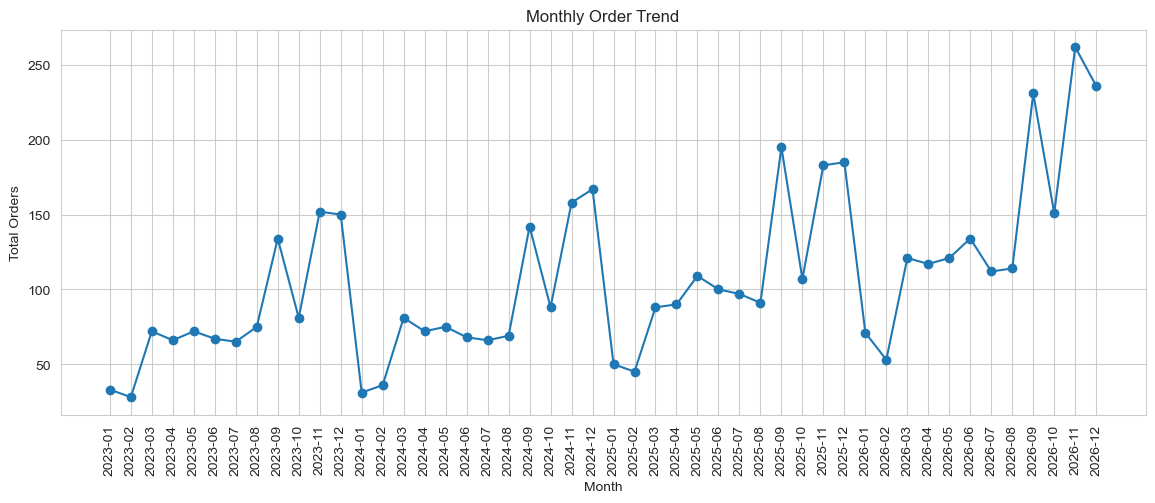

In [11]:
plt.figure(figsize=(14,5))

plt.plot(
    monthly_trend['Month'],
    monthly_trend['Order ID'],
    marker='o'
)

plt.title('Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Total Orders')
plt.xticks(rotation=90)
plt.show()